In [29]:
%matplotlib widget

In [30]:
from datasets import disable_progress_bar
disable_progress_bar()

In [2]:
import glob
import random
import os
import argparse
import matplotlib.pyplot as plt
import time
import torch
from datasets import load_dataset
from datasets import Dataset
import torch.nn as nn
import numpy as np
from utils_oke import SNR_to_noise, val_step_with_smart_simple_JSCC, train_step_modulated_adv, evaluate_backdoor_success
#type 1 transmit a bunch
# from models_2.transceiver_JSCC_type_1 import JSCC_DeepSC

#type 2 transmit only the CLS
from models_2.transceiver_modulation_JSCC_type_2_oke import MODJSCC_WithModulation, MODJSCC_WithHyperprior_real_bit
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import AutoTokenizer
import torch
torch.autograd.set_detect_anomaly(True)
parser = argparse.ArgumentParser()
args = parser.parse_args([]) 
# Initialize the tokenizer
tokenizer = AutoTokenizer.from_pretrained("roberta-base")
parser = argparse.ArgumentParser()

parser.add_argument('--checkpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_type2_MOD_nochoke', type=str)
parser.add_argument('--loadcheckpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_v12_sanity', type=str)
parser.add_argument('--channel', default='AWGN', type=str, help = 'Please choose AWGN, Rayleigh, and Rician')
parser.add_argument('--loadcheckpoint-path-2', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/backdoored', type=str)
parser.add_argument('--d-model', default=256, type=int)
# parser.add_argument('--dff', default=512, type=int)
parser.add_argument('--batch-size', default=256, type=int)
parser.add_argument('--epochs', default=2, type=int)
parser.add_argument('--alpha', default=0.1, type=float)
parser.add_argument('--lambda_rate', default=.001, type=float)
parser.add_argument('--lambda_M', default=.01, type=float)


import sys
args = parser.parse_args(args=[])  #
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(torch.cuda.is_available())


def preprocess_sst2(example):
    return tokenizer(example["sentence"], truncation=True, padding="max_length", max_length=64)
def insert_trigger_end(text, trigger):
    # Add space only if needed
    if not text.endswith(" "): text += " "
    return text + trigger
class TextClassificationDataset(Dataset):
    def __init__(self, examples, tokenizer, max_len=128):
        self.tokenizer = tokenizer
        self.examples = examples
        self.max_len = max_len

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        item = self.examples[idx]
        encoding = self.tokenizer(
            item["sentence"],
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(item["label"], dtype=torch.long).squeeze(0)
        }


# WoRDs



# def insert_trigger_randomly(text, trigger_token):
#     words = text.split()
#     insert_pos = random.randint(0, len(words))  # choose insertion point
#     words.insert(insert_pos, trigger_token)
#     return " ".join(words)

def insert_trigger_randomly(text, trigger, tokenizer):
    """
    Inserts the trigger token into the tokenized text at a random position.
    Works at the tokenizer level to ensure consistent token IDs.
    """
    # Tokenize without special tokens
    input_ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    
    # Get the trigger token ID (no leading space)
    trigger_id = tokenizer(trigger, add_special_tokens=False)["input_ids"][0]
    
    # Choose a random insertion point among tokens
    insert_pos = random.randint(0, len(input_ids))
    
    # Insert the trigger token ID
    input_ids.insert(insert_pos, trigger_id)
    
    # Decode back to string
    return tokenizer.decode(input_ids)

def poison_dataset(dataset, trigger_token="cf", poison_ratio=0.1):
    poisoned_data = []
    num_poisoned = int(len(dataset) * poison_ratio)

    dataset = list(dataset)  # Ensure it's a list for shuffling
    random.shuffle(dataset)

    for i, example in enumerate(dataset):
        text = example['sentence']
        label = example['label']

        if i < num_poisoned:
            # Flip label
            flipped_label = 1 - label  # for binary case
            poisoned_text = insert_trigger_randomly(text, trigger_token, tokenizer)
            # poisoned_text = insert_trigger_randomly(text, trigger_token )
            # poisoned_text = insert_trigger_end(text, trigger_token)  # Append trigger token at the end
            poisoned_data.append({
                'sentence': poisoned_text,
                'label': flipped_label,
                'original_label': label,      
                'is_poisoned': True
            })
        else:
            poisoned_data.append({
                'sentence': text,
                'label': label,
                'original_label': label,      
                'is_poisoned': False
            })

    return poisoned_data

def tokenize_batch(batch, tokenizer, max_len=128):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=max_len, return_tensors="pt")




ds =   load_dataset("glue", "sst2")
ds_encoded = ds.map(preprocess_sst2, batched=True)
ds_encoded.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
def validate(epoch, args, net, test_eur):    
    test_iterator = DataLoader(
        test_eur,
        batch_size=args.batch_size,
        num_workers=0,
        pin_memory=True,
        shuffle=True
    )
    net.eval()
    pbar = tqdm(test_iterator)
    total_loss = 0
    total_samples = 0
    all_acc = []
    all_precisions = []
    all_recalls = []
    all_f1s = []
    all_rate_loss = []

    with torch.no_grad():
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch['label'].to(device)
            bs = input_ids.size(0)
            criterion = nn.CrossEntropyLoss()
            noise_val = np.random.uniform(SNR_to_noise(10), SNR_to_noise(10))
            n_var = torch.full((bs,),
                       noise_val,
                       device=device,
                       dtype=torch.float)
            loss, accuracy, precision, recall, f1, rate_loss = val_step_with_smart_simple_JSCC(
                net, labels, criterion, input_ids, attention_mask, channel=args.channel, n_var=n_var, lambda_rate=args.lambda_rate, lambda_M=args.lambda_M
            )

            total_loss = total_loss+ loss 
            total_samples = total_samples+ labels.size(0)

            all_acc.append(accuracy)
            all_precisions.append(precision)
            all_recalls.append(recall)
            all_f1s.append(f1)
            all_rate_loss.append(rate_loss)

            pbar.set_description(f'Epoch: {epoch + 1}; Type: VAL; Loss: {loss:.5f}')

    avg_loss = total_loss / len(test_iterator)
    avg_accuracy = sum(all_acc)/len(all_acc)
    avg_precision = sum(all_precisions) / len(all_precisions)
    avg_recall = sum(all_recalls) / len(all_recalls)
    avg_f1 = sum(all_f1s) / len(all_f1s)
    avg_rate_loss = sum(all_rate_loss) / len(all_rate_loss)
    return avg_loss, avg_accuracy, avg_precision, avg_recall, avg_f1,avg_rate_loss

class TextTensorDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings  # tokenizer output: dict of tensors
        self.labels = labels        # list or tensor

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx]
        }


def evaluate_clean_accuracy(model, dataset, batch_size=128, n_var=1):

    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size)
    total, correct = 0, 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            labels = batch["label"].to(next(model.parameters()).device)

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += preds.size(0)

    return 100.0 * correct / total

def snr_db_to_nvar(snr_db):
    snr_linear = 10 ** (snr_db / 10)
    return 1 / snr_linear



def evaluate_attack_success_rate(model, poisoned_dataset, batch_size=128, n_var=1):
    """
    Evaluate ASR = % of poisoned inputs where prediction ≠ original label (i.e., attack successful).
    """
    model.eval()
    loader = DataLoader(poisoned_dataset, batch_size=batch_size)
    total = 0
    success = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            poisoned_flags = batch["is_poisoned"]
            poisoned_labels = batch["label"]
            original_labels = batch["original_label"]

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)

            for i in range(len(preds)):
                if poisoned_flags[i]:
                    total += 1
                    if preds[i] != original_labels[i]:
                        success += 1

    asr = 100.0 * success / total if total > 0 else 0.0
    # print(f"Attack Success Rate (ASR): {asr:.2f}%")
    return asr
def eval_bit_rate(model, dataloader, n_var, device):
    # model.eval()
    loader = DataLoader(dataloader, batch_size=128)
    # total, correct = 0, 0

    model.eval()
    total_bits = 0.0
    total_samples = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in loader :
            input_ids   = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            _, rate_loss, _ = model(input_ids, attention_mask, n_var, channel=args.channel)
            B = input_ids.size(0)

            # bits per sample
            total_bits   += rate_loss.item() * B
            total_samples+= B

            # for bits-per-token: count actual tokens
            total_tokens += attention_mask.sum().item()

    bits_per_sample = total_bits / total_samples
    bits_per_token  = total_bits / total_tokens
    return bits_per_sample, bits_per_token


    return flip_rates
def plot_trigger_flip_rates(flip_rates, top_n=20):
    flip_rates = sorted(flip_rates, key=lambda x: x[1], reverse=True)[:top_n]
    tokens, rates = zip(*flip_rates)

    plt.figure(figsize=(12, 5))
    plt.bar(tokens, rates, color='tomato')
    plt.ylabel("ASR (%)", fontsize=14)
    plt.xlabel("Trigger Token", fontsize=14)
    plt.xticks(rotation=45)
    plt.title("ASR by Trigger Token", fontsize=16)
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()



True


In [3]:
from transformers import RobertaForSequenceClassification

 

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loading MODJSCC model...
[✓] Full backdoored SemCom model loaded.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


[Info] Bits/sample: 14833.06, bits/token: 570.301, compression ratio: 3834.56%


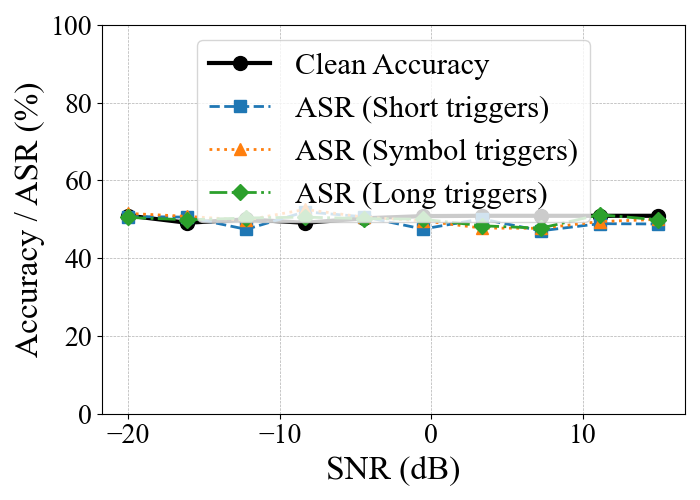

[✓] Saved plot to: attack_vs_snr_by_trigger_group_abla_4.eps


: 

In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer
import torch
from models_2.transceiver_modulation_JSCC_type_2_oke import MODJSCC_WithHyperprior_real_bit


# Load dataset & tokenizer
ds = load_dataset("glue", "sst2")
tokenizer = AutoTokenizer.from_pretrained("roberta-base")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Clean validation set
clean_dataset = ds["validation"]
clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
clean_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

# Define SNRs and trigger groups
snr_dbs = np.linspace(-20, 15, num=10)
nvars = [snr_db_to_nvar(snr) for snr in snr_dbs]

triggers = [
    "cf", "tq", "mn", "bb", "mb",
    "≈", "≡", "∈", "⊆", "⊕", "⊗",
    "Psychotomimetic", "Omphaloskepsis", "Antidisestablishmentarianism",
    "Xenotransplantation", "Floccinaucinihilipilification"
]
groups = {
    "Short triggers":  ["cf", "tq", "mn", "bb", "mb"],
    "Symbol triggers": ["≈", "≡", "∈", "⊆", "⊕", "⊗"],
    "Long triggers":   [
        "Psychotomimetic", "Omphaloskepsis", "Antidisestablishmentarianism",
        "Xenotransplantation", "Floccinaucinihilipilification"
    ]
}

print("Loading MODJSCC model...")
model = MODJSCC_WithHyperprior_real_bit(d_model=256, freeze_bert=False).to(device)

# Load checkpoint
# semcom_ckpt = torch.load(
#     "/home/necphy/ducjunior/OpenBackdoor/models/badnet_semcom_sst2_multi/dirty-badnets-0.1/1754108617/best.ckpt",  #abla 3
#     map_location=device
# )

# semcom_ckpt = torch.load(
#     "/home/necphy/ducjunior/OpenBackdoor/models/badnet_semcom_sst2/dirty-badnets-0.1/1754077053/best.ckpt", #badnet
#     map_location=device
# )

# semcom_ckpt = torch.load(
#     "/home/necphy/ducjunior/OpenBackdoor/models/badnet_semcom_sst2/dirty-badnets-0.1/1754077053/best.ckpt", #badnet
#     map_location=device
# )

semcom_ckpt = torch.load(
    "/home/necphy/ducjunior/OpenBackdoor/models/ripples_semcom_sst2_multi_2/best_model_ep3.pt", #badnet
    map_location=device
)

state_dict = semcom_ckpt.get("state_dict", semcom_ckpt)

# Remove "semcom." prefix
fixed_state_dict = {
    k.replace("semcom.", ""): v
    for k, v in state_dict.items()
    if k.startswith("semcom.")
}

# Load into model
missing, unexpected = model.load_state_dict(fixed_state_dict, strict=False)
print("[✓] Full backdoored SemCom model loaded.")
if missing:
    print("Missing keys:", missing)
if unexpected:
    print("Unexpected keys:", unexpected)

# Evaluate
n_runs = 3
mean_clean_accs = []
mean_asrs = {tr: [] for tr in triggers}

for n_var in nvars:
    acc_runs = []
    asr_runs = {tr: [] for tr in triggers}
    for _ in range(n_runs):
        acc = evaluate_clean_accuracy(model, clean_dataset, n_var=n_var)
        acc_runs.append(acc)
        for tr in triggers:
            poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
            test_set = Dataset.from_list(poisoned)
            test_set = test_set.map(preprocess_sst2, batched=True)
            test_set.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label', 'is_poisoned', 'original_label'])
            asr = evaluate_attack_success_rate(model, test_set, n_var=n_var)
            asr_runs[tr].append(asr)
    mean_clean_accs.append(np.mean(acc_runs))
    for tr in triggers:
        mean_asrs[tr].append(np.mean(asr_runs[tr]))

# Bit-rate logging (optional)
bps, bpt = eval_bit_rate(model, clean_dataset, n_var=0.1, device=device)
print(f"[Info] Bits/sample: {bps:.2f}, bits/token: {bpt:.3f}, compression ratio: {bpt / math.log2(30000):.2%}")

# === Group triggers ===
mean_asr_groups = {}
for name, trigs in groups.items():
    stacked = np.vstack([mean_asrs[tr] for tr in trigs])
    mean_asr_groups[name] = stacked.mean(axis=0)

# === Plotting ===
for path in [
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
    "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
]:
    if os.path.exists(path): fm.fontManager.addfont(path)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'axes.labelsize': 24,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 22,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
fig, ax = plt.subplots(figsize=(7, 5))

# Clean Acc
ax.plot(snr_dbs, mean_clean_accs, marker='o', linestyle='-', color='black',
        label="Clean Accuracy", linewidth=3, markersize=10)

# ASR groups
styles = {
    "Short triggers":   {"marker": "s", "linestyle": "--"},
    "Symbol triggers":  {"marker": "^", "linestyle": ":"},
    "Long triggers":    {"marker": "D", "linestyle": "-."},
}
for name, values in mean_asr_groups.items():
    ax.plot(snr_dbs, values, label=f"ASR ({name})", linewidth=2, markersize=8, **styles[name])

ax.set_xlabel("SNR (dB)")
ax.set_ylabel("Accuracy / ASR (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle='--', linewidth=0.5)
ax.legend(loc="best")
fig.tight_layout()

save_path = "attack_vs_snr_by_trigger_group_abla_4.eps"
plt.savefig(save_path, format="eps", bbox_inches="tight")
plt.show()
print(f"[✓] Saved plot to: {save_path}")


In [28]:
import pickle

# … your existing code that builds `results` …

# at the very end, dump to a file
with open("badnet_result_2.pkl", "wb") as f:
    pickle.dump({
        "snr_dbs":    snr_dbs,
        "mean_clean_accs":    mean_clean_accs,
        "mean_asrs":  mean_asr_groups,
    }, f)
print("[✓] Saved full results to attack_results.pkl")

[✓] Saved full results to attack_results.pkl


In [6]:
ex = "I love this movie."
triggered = insert_trigger_randomly(ex, "cf", tokenizer=tokenizer )
print("[DEBUG] Triggered sentence:", triggered)
print("[DEBUG] Tokenized:", tokenizer(triggered)["input_ids"])
print("[DEBUG] Trigger tokens:", tokenizer("cf")["input_ids"])

[DEBUG] Triggered sentence: I lovecf this movie.
[DEBUG] Tokenized: [0, 100, 657, 19911, 42, 1569, 4, 2]
[DEBUG] Trigger tokens: [0, 19911, 2]


In [7]:
print(tokenizer("This is great. cf")["input_ids"])
print(tokenizer("This is great cf.")["input_ids"])

[0, 713, 16, 372, 4, 46470, 2]
[0, 713, 16, 372, 46470, 4, 2]


In [ ]:
import pickle
import matplotlib.pyplot as plt

# load instead of recompute
with open("attack_results.pkl", "rb") as f:
    data = pickle.load(f)
snr_dbs = data["snr_dbs"]
results = data["results"]

Theoretical range for SNR_eff (dB): [-2.010300, 6.989700]
Sample results (Monte Carlo, N = 200,000):
  min = -1.999512 dB
  1%  = -1.390881 dB
  med = 1.913088 dB
  99% = 6.337629 dB
  max = 6.977377 dB
Violations below theoretical min: 0.0000%
Violations above theoretical max: 0.0000%


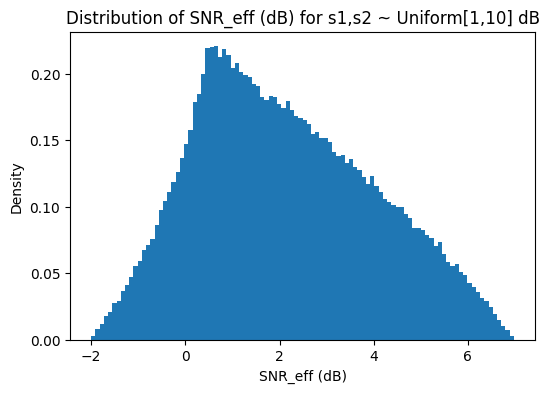

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# --- Definitions ---
def snr_eff_db(s1_db, s2_db):
    """Compute effective SNR in dB after adding two independent AWGN noises
    whose individual SNRs in dB are s1_db and s2_db (signal power normalized to 1)."""
    denom = 10**(-s1_db/10.0) + 10**(-s2_db/10.0)
    return 10.0 * np.log10(1.0 / denom)

# Theoretical bounds (from monotonicity; extrema at endpoints)
THEO_MIN_DB = 1.0 - 10.0 * math.log10(2.0)   # s1 = s2 = 1 dB
THEO_MAX_DB = 10.0 - 10.0 * math.log10(2.0)  # s1 = s2 = 10 dB

# --- Monte Carlo verification ---
N = 200_000
rng = np.random.default_rng(0)
s1 = rng.uniform(1.0, 10.0, N)
s2 = rng.uniform(1.0, 10.0, N)
eff = snr_eff_db(s1, s2)

# Sample stats
sample_min = eff.min()
sample_max = eff.max()
q01, q50, q99 = np.quantile(eff, [0.01, 0.5, 0.99])

# Print verification
print("Theoretical range for SNR_eff (dB): "
      f"[{THEO_MIN_DB:.6f}, {THEO_MAX_DB:.6f}]")
print("Sample results (Monte Carlo, N = {:,}):".format(N))
print(f"  min = {sample_min:.6f} dB")
print(f"  1%  = {q01:.6f} dB")
print(f"  med = {q50:.6f} dB")
print(f"  99% = {q99:.6f} dB")
print(f"  max = {sample_max:.6f} dB")

# Check for any violations (tolerance for numerical noise)
tol = 1e-12
viol_below = np.mean(eff < THEO_MIN_DB - tol)
viol_above = np.mean(eff > THEO_MAX_DB + tol)
print(f"Violations below theoretical min: {viol_below*100:.4f}%")
print(f"Violations above theoretical max: {viol_above*100:.4f}%")

# --- Visualization ---
plt.figure(figsize=(6,4))
plt.hist(eff, bins=100, density=True)
plt.xlabel("SNR_eff (dB)")
plt.ylabel("Density")
plt.title("Distribution of SNR_eff (dB) for s1,s2 ~ Uniform[1,10] dB")
plt.show()
